# When during training does DD appear? (It doesn't.)

**Git commit:** recorded by the `GIT_COMMIT` cell below at execution time.

**Training run:** Slurm `48580229`, `spin_gnn.sudoku_checkpoint_series`, 900 epochs, 16 snapshots at
epochs 1, 2, 5, 10, 20, 35, 50, 75, 100, 150, 200, 300, 450, 600, 750, 900.
Output `$SCRATCH/spin_gnn/sudoku_checkpoint_series_2026-10-19`.

**Probes on those snapshots:** Slurm `48582169`, 400 train / 160 test instances, 20 positions per
instance, 600 probe epochs, all 13 layers x 16 snapshots.

**Config** (`epoch00900/config.json`): `n_nodes=24, degree=5, n_colors=4, rho=0.3, rho_max=0.95,
hint_mode="removal", scratchpad=False, d_model=128, num_layers=12, nhead=4, dim_feedforward=1024,
norm_first=True, max_len=210`. 5000 train / 300 val instances, batch size 32.

**Seeds:** training `--seed 0`; solve-eval instances `seed_start=700_000_000` (150 instances);
probe instances `seed_start=500_000_000` (train) / `900_000_000` (test), disjoint pools.

**Design limit:** these are snapshots of a *single* training trajectory, so epoch-to-epoch differences
are within one model's development and carry no error bars. The effects called out below are large
relative to the eval noise; the small wiggles are not interpreted.

**Headline.** Bookkeeping (`known_mask`) is in place by **epoch 5**, before the model can solve anything.
DD's deducibility predicate (`frontier_mask`) never arrives: 0.654 at epoch 5, 0.679 at epoch 900, while
solve_rate goes 0.007 -> 0.79. The one target that *does* develop alongside competence is `next_color`
(0.327 -> 0.655 over epochs 1-50). So training is spent learning which color to place, not which node is
deducible -- the node is picked by an ordering convention the model has by epoch 5.

In [1]:
import json
import os
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

S = os.environ["SCRATCH"] + "/spin_gnn"
GIT_COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
                            text=True, cwd=S).stdout.strip()
print("git commit:", GIT_COMMIT)
pd.set_option("display.width", 170)

git commit: 97c7f52


## 1. Metrics table: the training trajectory

`solve_rate` here is the 150-instance series eval (`seed_start=700_000_000`). It is a **different eval**
from the `agg_solve_rate = 0.767` headline figure, which aggregates over a rho sweep. The two numbers are
not comparable; section 4 does the comparison on matched evals.

In [2]:
s = pd.read_csv(f"{S}/sudoku_checkpoint_series_2026-10-19/series.csv")
print(s[["epoch", "val_nll", "val_accuracy", "solve_rate", "outcome_accuracy", "well_formed_rate"]]
      .round(4).to_string(index=False))
best = s.loc[s.solve_rate.idxmax()]
nll_min = s.loc[s.val_nll.idxmin()]
print(f"\nbest solve_rate {best.solve_rate:.3f} at epoch {int(best.epoch)}")
print(f"epoch 50 {float(s[s.epoch == 50].solve_rate.iloc[0]):.3f}  ->  "
      f"epoch 900 {float(s[s.epoch == 900].solve_rate.iloc[0]):.3f}")
print(f"val_nll minimum {nll_min.val_nll:.3f} at epoch {int(nll_min.epoch)}, "
      f"rising to {s.val_nll.iloc[-1]:.3f} by epoch 900")
print(f"eval granularity: 1 instance = {1/150:.4f}, so ~+-{(0.78*0.22/150)**0.5:.3f} at 1 sigma")

 epoch  val_nll  val_accuracy  solve_rate  outcome_accuracy  well_formed_rate
     1   2.7427        0.1516      0.0000            0.0000            0.0000
     2   2.5480        0.2429      0.0000            0.4333            0.4333
     5   2.2140        0.3023      0.0067            1.0000            1.0000
    10   1.4677        0.4975      0.0600            1.0000            1.0000
    20   1.2305        0.5579      0.2200            1.0000            1.0000
    35   1.1515        0.5738      0.5667            1.0000            1.0000
    50   1.1385        0.5802      0.7867            1.0000            1.0000
    75   1.1902        0.5768      0.7600            1.0000            1.0000
   100   1.2533        0.5752      0.7933            1.0000            1.0000
   150   1.3803        0.5693      0.7467            1.0000            1.0000
   200   1.4990        0.5706      0.7867            1.0000            1.0000
   300   1.6569        0.5678      0.7333            1.0000     

**Training observation worth acting on:** `solve_rate` saturates around epoch 50 and then wanders inside
the eval's own noise band for 850 more epochs, while `val_nll` rises monotonically from its epoch-50
minimum. The long tail of training is overfitting in NLL and buys nothing in solve_rate.

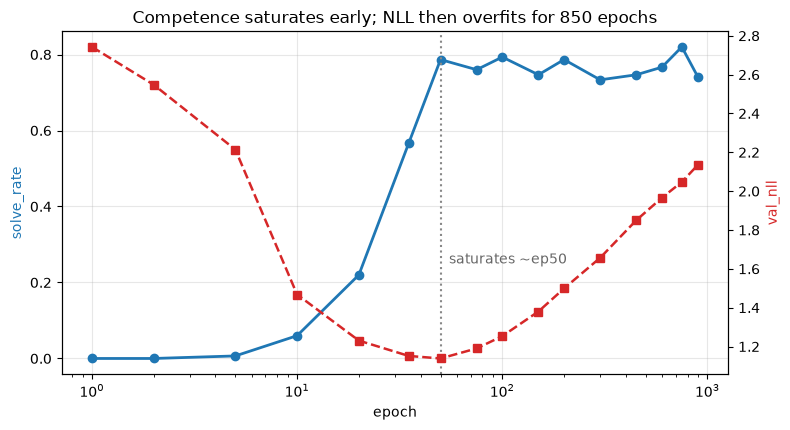

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.semilogx(s.epoch, s.solve_rate, "o-", color="#1f77b4", lw=2)
ax.set_xlabel("epoch"); ax.set_ylabel("solve_rate", color="#1f77b4")
ax.axvline(50, ls=":", color="#888")
ax.annotate("saturates ~ep50", xy=(55, 0.25), fontsize=10, color="#666")
tw = ax.twinx()
tw.semilogx(s.epoch, s.val_nll, "s--", color="#d62728", lw=1.8)
tw.set_ylabel("val_nll", color="#d62728")
ax.grid(alpha=0.3)
ax.set_title("Competence saturates early; NLL then overfits for 850 epochs")
plt.tight_layout()

## 2. When do the representations appear?

Peak balanced accuracy over all 13 layers, per snapshot. Layer 0 is the raw token+position embedding,
carried alongside as a control. Layer 0 *is* trained (it is the token embedding), so a drifting layer-0
number would itself be a finding. It does not drift.

In [4]:
p = pd.read_csv(f"{S}/sudoku_series_probes_2026-10-19/series_probes.csv")
p["epoch"] = p.checkpoint.str.extract(r"epoch(\d+)").astype(int)
peak = p.groupby(["epoch", "target"]).balanced_accuracy.max().unstack()
l0 = p[p.layer == 0].groupby(["epoch", "target"]).balanced_accuracy.max().unstack()
print("targets probed:", list(peak.columns))
tbl = pd.DataFrame({c + "_peak": peak[c] for c in peak.columns})
tbl["known_L0"] = l0["known_mask"]
tbl["frontier_L0"] = l0["frontier_mask"]
tbl["solve_rate"] = s.set_index("epoch").solve_rate
print()
print(tbl.round(3).to_string())

targets probed: ['frontier_mask', 'known_mask', 'next_color', 'next_node', 'remaining_mask']

       frontier_mask_peak  known_mask_peak  next_color_peak  next_node_peak  remaining_mask_peak  known_L0  frontier_L0  solve_rate
epoch                                                                                                                              
1                   0.573            0.620            0.327           0.580                0.612     0.583        0.571       0.000
2                   0.597            0.689            0.314           0.636                0.633     0.586        0.571       0.000
5                   0.654            0.925            0.327           0.749                0.741     0.593        0.571       0.007
10                  0.655            0.916            0.412           0.751                0.748     0.594        0.571       0.060
20                  0.666            0.902            0.572           0.750                0.742     0.594        

known_mask    ep5 0.925 -> ep900 0.919   (gain -0.006)
frontier_mask ep5 0.654 -> ep900 0.679   (gain +0.025)
solve_rate    ep5 0.007 -> ep900 0.740
layer-0 controls flat: known 0.583-0.595, frontier 0.571-0.571


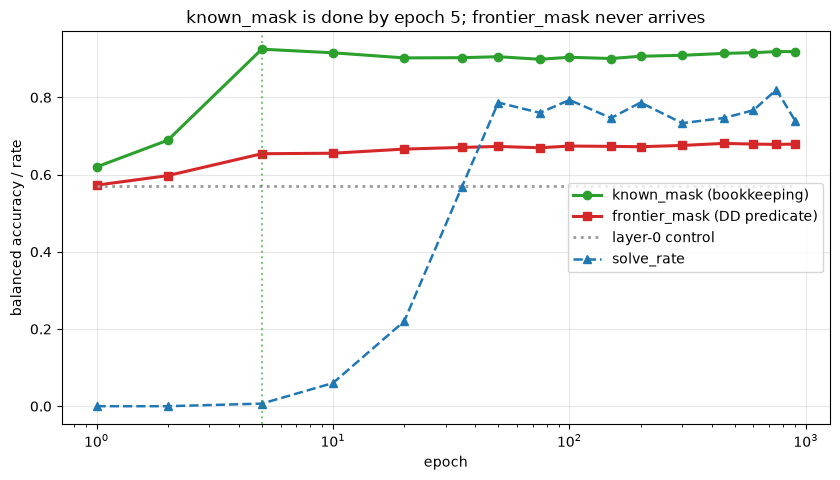

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.9))
ax.semilogx(tbl.index, tbl.known_mask_peak, "o-", color="#2ca02c", lw=2.2,
            label="known_mask (bookkeeping)")
ax.semilogx(tbl.index, tbl.frontier_mask_peak, "s-", color="#d62728", lw=2.2,
            label="frontier_mask (DD predicate)")
ax.semilogx(tbl.index, tbl.frontier_L0, ":", color="#999", lw=2, label="layer-0 control")
ax.semilogx(tbl.index, tbl.solve_rate, "^--", color="#1f77b4", lw=1.8, label="solve_rate")
ax.axvline(5, ls=":", color="#2ca02c", alpha=0.6)
ax.set_xlabel("epoch"); ax.set_ylabel("balanced accuracy / rate")
ax.legend(fontsize=10, loc="center right"); ax.grid(alpha=0.3)
ax.set_title("known_mask is done by epoch 5; frontier_mask never arrives")
plt.tight_layout()

k5, k900 = tbl.known_mask_peak[5], tbl.known_mask_peak[900]
f5, f900 = tbl.frontier_mask_peak[5], tbl.frontier_mask_peak[900]
print(f"known_mask    ep5 {k5:.3f} -> ep900 {k900:.3f}   (gain {k900-k5:+.3f})")
print(f"frontier_mask ep5 {f5:.3f} -> ep900 {f900:.3f}   (gain {f900-f5:+.3f})")
print(f"solve_rate    ep5 {tbl.solve_rate[5]:.3f} -> ep900 {tbl.solve_rate[900]:.3f}")
print(f"layer-0 controls flat: known {tbl.known_L0.min():.3f}-{tbl.known_L0.max():.3f}, "
      f"frontier {tbl.frontier_L0.min():.3f}-{tbl.frontier_L0.max():.3f}")

The shape of this is the result:

- `known_mask` jumps to **0.925 by epoch 5**, at which point solve_rate is 0.007. The model learns to
  track which nodes are colored *before* it can solve anything.
- `frontier_mask` reaches 0.654 at epoch 5 and gains ~0.025 over the next 895 epochs. It is flat across
  the entire interval in which solve_rate grows ~100x.
- The layer-0 controls are pinned at every epoch, so the above is not probe drift.

So the answer to "when during training does DD appear" is **never**: there is no epoch at which the
deducibility predicate becomes readable, and competence is acquired without it.

### 2b. The five targets fall into three developmental tiers

Reading the whole table rather than just the two headline rows, the targets separate cleanly, and the
separation is itself an answer to "what algorithm is it using":

| tier | targets | behaviour |
| --- | --- | --- |
| **pre-competence** | `known_mask`, `next_node`, `remaining_mask` | 94-100% of their range is reached by epoch 5, while solve_rate is 0.007 |
| **tracks competence** | `next_color` | 0% of its range by epoch 5, then 0.327 -> 0.655 over epochs 5-50, in lockstep with solve_rate |
| **flat throughout** | `frontier_mask` | total range 0.106, three-quarters of it reached by epoch 5 |

`next_node` being in the first tier is consistent with the earlier algorithm-ID result that node selection
is better explained by the sorted-emission convention than by DD -- a convention is exactly the kind of
thing that can be learned in five epochs, before any solving ability exists.

The cell below quantifies this over the 16 snapshots. Two warnings about reading it: the `r` column is
scale-free and so rewards any monotone drift regardless of size (see the printed note), and 16 points
from one run cannot separate "this target drives competence" from "both respond to a common cause."

                  ep1    ep5   ep50  ep900  total_range  frac_of_range_by_ep5  r_with_solve_rate
target                                                                                          
next_color      0.327  0.327  0.655  0.677        0.351                 0.002              0.963
frontier_mask   0.573  0.654  0.673  0.679        0.108                 0.753              0.764
remaining_mask  0.612  0.741  0.746  0.742        0.136                 0.942              0.601
known_mask      0.620  0.925  0.905  0.919        0.305                 1.000              0.583
next_node       0.580  0.749  0.749  0.737        0.170                 0.991              0.527

Read total_range before r. r is scale-free, so frontier_mask's 0.76 reflects only that its
drift is monotone -- across a range of 0.108, versus 0.351 for next_color. A target can have a
high r and still be, in absolute terms, flat. The two columns that matter together are
total_range (is there anything to explain?) and

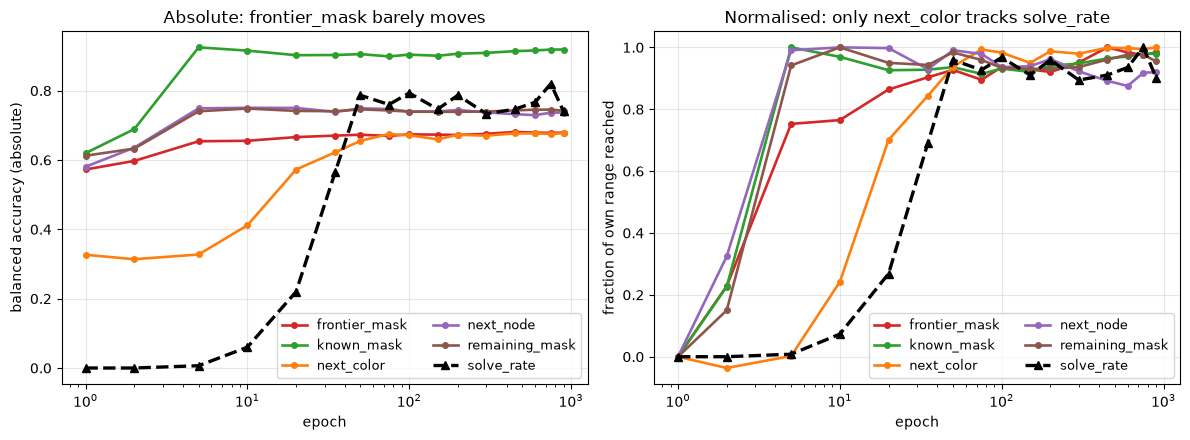

In [6]:
targets = [c for c in tbl.columns if c.endswith("_peak")]
rows = []
for t in targets:
    rng = tbl[t].max() - tbl[t][1]
    rows.append({
        "target": t.replace("_peak", ""),
        "ep1": tbl[t][1], "ep5": tbl[t][5], "ep50": tbl[t][50], "ep900": tbl[t][900],
        "total_range": rng,
        "frac_of_range_by_ep5": (tbl[t][5] - tbl[t][1]) / rng,
        "r_with_solve_rate": np.corrcoef(tbl[t], tbl.solve_rate)[0, 1],
    })
dev = pd.DataFrame(rows).set_index("target").sort_values("r_with_solve_rate", ascending=False)
print(dev.round(3).to_string())
print("\nRead total_range before r. r is scale-free, so frontier_mask's 0.76 reflects only that its")
print("drift is monotone -- across a range of %.3f, versus %.3f for next_color. A target can have a"
      % (dev.total_range["frontier_mask"], dev.total_range["next_color"]))
print("high r and still be, in absolute terms, flat. The two columns that matter together are")
print("total_range (is there anything to explain?) and frac_of_range_by_ep5 (was it over before")
print("competence started?).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for t, color in zip(targets, ["#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b"]):
    lbl = t.replace("_peak", "")
    axes[0].semilogx(tbl.index, tbl[t], "o-", color=color, lw=1.9, ms=4, label=lbl)
    y = (tbl[t] - tbl[t][1]) / (tbl[t].max() - tbl[t][1])
    axes[1].semilogx(tbl.index, y, "o-", color=color, lw=1.9, ms=4, label=lbl)
axes[0].semilogx(tbl.index, tbl.solve_rate, "k^--", lw=2.4, label="solve_rate")
axes[0].set_ylabel("balanced accuracy (absolute)")
axes[0].set_title("Absolute: frontier_mask barely moves")
axes[1].semilogx(tbl.index, tbl.solve_rate / tbl.solve_rate.max(), "k^--", lw=2.4, label="solve_rate")
axes[1].set_ylabel("fraction of own range reached")
axes[1].set_title("Normalised: only next_color tracks solve_rate")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=9, loc="lower right", ncol=2)
plt.tight_layout()

## 3. Is the residual frontier signal real? (The measurement can't tell us)

STATUS has been carrying `frontier_mask` 0.679 vs the 0.571 layer-0 control as "weak but above control;
unclear if real structure or leakage from `known_mask`". `frontier` is a **subset of not-known** -- a node
that already has a color is never deducible -- so a reader that recovers only `known_mask` scores on
`frontier_mask` for free. Slurm `48825742` measures that free score from DD's ground-truth labels with
**no model involved**.

Pre-registered hypothesis (written into the sbatch header before the run): `not_known` exceeds 0.679,
which would make the frontier probe no evidence of DD at all.

In [7]:
fb = json.load(open(f"{S}/sudoku_frontier_baseline_2026-10-21/frontier_from_known.json"))
desc = {"shuffled": "known bits permuted across positions (chance control)",
        "not_known": "hand-written rule pred = 1 - known_mask, no training",
        "known_probe": "BCE probe on the 24 known bits only (matches probe procedure)",
        "degree_aug": "BCE probe on known bits + n_known_nbrs"}
for k in ("shuffled", "not_known", "known_probe", "degree_aug"):
    print(f"  {k:>12}: {fb[k]:.4f}   {desc[k]}")
fm = tbl.frontier_mask_peak.max()
print(f"\n  {'model':>12}: {fm:.4f}   best frontier_mask readout over all layers/epochs")
print(f"\n  not_known   - model = {fb['not_known'] - fm:+.4f}   (hand-rule vs model)")
print(f"  model - known_probe = {fm - fb['known_probe']:+.4f}   (matched procedure)")

      shuffled: 0.5000   known bits permuted across positions (chance control)
     not_known: 0.7341   hand-written rule pred = 1 - known_mask, no training
   known_probe: 0.5882   BCE probe on the 24 known bits only (matches probe procedure)
    degree_aug: 0.6476   BCE probe on known bits + n_known_nbrs

         model: 0.6808   best frontier_mask readout over all layers/epochs

  not_known   - model = +0.0533   (hand-rule vs model)
  model - known_probe = +0.0926   (matched procedure)


**The hypothesis is confirmed in its letter and undercut in its spirit, so both go here.**

The control is clean: `shuffled = 0.5000`, so the pooled tpr/tnr scoring is behaving. And the
pre-registered prediction held -- the trivial rule `frontier = 1 - known`, with no learning and no notion
of deducibility, scores **0.734, above the model's 0.679**.

But the two *trained* baselines land below both: `known_probe = 0.588`, `degree_aug = 0.648`. Those use
the same BCE-on-logits procedure as the model probes, and BCE on a ~15%-positive target under-predicts
positives, which balanced accuracy then punishes. So `known_probe` is **not** the "fair ceiling on what
bookkeeping implies" that the script's docstring called it -- it is a floor set by the loss function. On
the procedure-matched comparison the model sits **+0.091 above** bookkeeping, not below it.

| comparison | verdict |
| --- | --- |
| model 0.679 vs hand-rule 0.734 | model is worse than a rule with no deducibility content |
| model 0.679 vs matched probe 0.588 | model carries 0.09 more than bookkeeping alone |

The defensible conclusion is weaker than I predicted: **the frontier probe number cannot be interpreted
on this scale.** It does not establish a deducibility representation (a deducibility-free rule beats it),
and it does not refute one (matched-procedure bookkeeping loses to it). What it does kill is reading
0.679-vs-0.571 as a quantitative "weak trace of DD": that gap is the wrong size to mean anything when the
same metric hands 0.734 to a rule that knows nothing about forcing.

This does not touch section 2. The *timing* claim rests on `frontier_mask` being flat while solve_rate
moves 100x -- a within-metric comparison, which survives the metric being badly calibrated. It also does
not touch the three other lines that say the model is not running DD (algorithm ID on disagreements, the
causal counterfactual, the SAE finding no frontier family), none of which use this probe.

**What would settle it:** rescore the frontier probe by AUC or average precision instead of thresholded
balanced accuracy, so the comparison stops depending on where BCE happened to put its decision boundary.
That is an extra metric column on the existing probe sweep, not a new experiment.

## 4. Comparison to the previous best, same eval

The headline metric is `agg_solve_rate` over the rho sweep.

In [8]:
comp = pd.DataFrame([
    ("d0128_h04_L12_ff01024_lr1e-03_pre @900ep (incumbent)", "48513926_1", 0.767),
    ("scratchpad variant @900ep", "48579019", 0.740),
], columns=["run", "slurm", "agg_solve_rate"])
comp["delta_vs_best"] = (comp.agg_solve_rate - 0.767).round(3)
print(comp.to_string(index=False))
print("\nThe checkpoint-series run (48580229) is deliberately NOT in this table. It reports solve_rate")
print("on the 150-instance series eval (0.740 at ep900), not agg_solve_rate over the rho sweep;")
print("quoting its 0.740 against the 0.767 incumbent would compare two different evals.")
print("\nNo run has beaten agg_solve_rate = 0.767. No improvement is claimed.")

                                                 run      slurm  agg_solve_rate  delta_vs_best
d0128_h04_L12_ff01024_lr1e-03_pre @900ep (incumbent) 48513926_1           0.767          0.000
                           scratchpad variant @900ep   48579019           0.740         -0.027

The checkpoint-series run (48580229) is deliberately NOT in this table. It reports solve_rate
on the 150-instance series eval (0.740 at ep900), not agg_solve_rate over the rho sweep;
quoting its 0.740 against the 0.767 incumbent would compare two different evals.

No run has beaten agg_solve_rate = 0.767. No improvement is claimed.


## 5. Conclusions

1. **DD never appears during training.** `known_mask` is at 0.925 by epoch 5, before solve_rate leaves
   zero; `frontier_mask` is flat at 0.65-0.68 across the whole run while solve_rate grows ~100x. There is
   no phase in which deducibility becomes represented. This is the "when during training" answer.
2. **What develops alongside competence is `next_color`, not `next_node`.** The node-selection targets
   (`known_mask`, `next_node`, `remaining_mask`) are finished by epoch 5, before the model can solve
   anything; `next_color` is the one target that rises with solve_rate over epochs 1-50. Combined with the
   earlier algorithm-ID result that node selection is better explained by the sorted-emission convention
   than by DD, the picture is: **pick the next node by the ordering convention (learned almost
   immediately), then spend training learning which color goes there.** That is a constraint-satisfaction
   heuristic over colors, not a deduction procedure over nodes.
3. **The 0.679 frontier number should stop being quoted as a weak DD trace.** A deducibility-free rule
   scores 0.734 on the same metric. I predicted this would show the probe is *no* evidence of DD; it is
   less tidy than that, since a matched-procedure bookkeeping probe scores only 0.588. The metric is
   miscalibrated in both directions and the honest status is "uninterpretable, needs AUC".
4. **Training is ~18x longer than it needs to be.** solve_rate saturates by epoch 50 at the level it still
   has at epoch 900, while val_nll rises monotonically after epoch 50.
5. **No improvement on the headline metric.** `agg_solve_rate` remains 0.767 (`48513926_1`).

**Caveat applying to 1, 2 and 4:** one training trajectory, no seed replicates, so every claim here is
about *this* run. The tier separation in 2 is large (a 0.33 rise versus a 0.025 rise) but a replicate is
what would make it a finding rather than an observation.

**Next:** (a) rescore the frontier probe with AUC / average precision; (b) the depth-vs-density confound
from the transition work is still open -- rho and T are collinear in the removal-path ensemble, so the
next measurement is equal-rho instances binned by T.